**Projet no. 6 :** Étudier et implanter l'algorithme EM pour un mélange de gaussiennes, en m'appuyant sur le notebook de la lecture 19 d'EE227C (partie EM). Étudier numériquement l'effet de l'initialisation, du critère d'arrêt et de la séparation des composantes, puis comparer avec des variantes et une alternative.

**sources du cours que j'utilise :**
 - Le cours de mr.Julien Jaques*Model-based clustering and classification, MBCC- partie 1* : log-vraisemblance (p. 46), étapes E et M (p. 47-49), propriétés et initialisation (p. 50), preuve de convergence (p. 51-54), exercice 3 (p. 55), variantes CEM et SEM (p. 56-57) ;
 - notes EE227C, chap. 19 « Alternating minimization and EM » : le texte renvoie surtout au notebook, il n'y a pas de théorie détaillée dans les notes sur ce point.


## Préparation

In [1]:

%matplotlib inline
import warnings; warnings.filterwarnings('ignore')
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import logsumexp
from sklearn.mixture import GaussianMixture

np.random.seed(1)               # graine globale, comme dans le notebook d'origine
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 30)
plt.rcParams.update({'font.size': 11, 'axes.grid': True, 'grid.alpha': .3})

### Ma boîte à outils
EM général (K composantes), variante CEM, initialisations, stratégie « plusieurs EM courts » de MBCC p. 50, maximisation directe par L-BFGS (gradient analytique), mesures d'erreur.

In [2]:
"""
Notation: theta = (pi, mu, sg)  avec pi: poids, mu: moyennes, sg: ecarts-types (tableaux de longueur K).
Log-vraisemblance (observations seules):  l(theta) = sum_i log sum_k pi_k N(x_i; mu_k, sg_k^2)
"""
import numpy as np
from scipy.special import logsumexp


def sample_gmm(rng, n, pi, mu, sg):
    pi, mu, sg = map(np.asarray, (pi, mu, sg))
    z = rng.choice(len(pi), size=n, p=pi)
    x = rng.normal(mu[z], sg[z])
    return x, z


def log_joint(X, pi, mu, sg):
    """(n, K) : log pi_k + log N(x_i; mu_k, sg_k^2)"""
    d = (X[:, None] - mu[None, :]) / sg[None, :]
    return -0.5 * d ** 2 - 0.5 * np.log(2 * np.pi) - np.log(sg)[None, :] + np.log(pi)[None, :]


def loglik(X, theta):
    pi, mu, sg = theta
    return float(logsumexp(log_joint(X, pi, mu, sg), axis=1).sum())


def responsibilities(X, theta):
    lj = log_joint(X, *theta)
    ll = logsumexp(lj, axis=1)
    return np.exp(lj - ll[:, None]), float(ll.sum())


def m_step(Q, X, var_floor=0.0):
    """M-step CORRECT : sigma_k^2 = sum_i q_ik (x_i - mu_k)^2 / sum_i q_ik  (cf. MBCC p.49)."""
    Nk = Q.sum(axis=0)
    pi = Nk / Nk.sum()
    mu = Q.T @ X / Nk
    var = (Q * (X[:, None] - mu[None, :]) ** 2).sum(axis=0) / Nk
    sg = np.sqrt(np.maximum(var, var_floor))
    return pi, mu, sg


def m_step_notebook(Q, X, var_floor=0.0):
    """M-step TEL QUE DANS LE NOTEBOOK : (q_ik (x_i - mu_k))^2 -> q au CARRE dans la variance."""
    Nk = Q.sum(axis=0)
    pi = Nk / Nk.sum()
    mu = Q.T @ X / Nk
    d = (X[:, None] - mu[None, :]) * Q
    var = (d ** 2).sum(axis=0) / Nk
    return pi, mu, np.sqrt(np.maximum(var, var_floor))


def run_em(X, theta0, max_iter=1000, tol=1e-9, hard=False, var_floor=0.0, mstep=m_step):
    """EM (hard=False) ou CEM (hard=True : responsabilites arrondies, MBCC p.56).
    Critere d'arret : |l_k - l_{k-1}| / n < tol (variation de la log-vraisemblance MOYENNE).
    Renvoie dict(theta, ll (historique de l(theta_k), k=0..), n_iter, converged, degenerate)."""
    n = len(X)
    theta = tuple(np.array(t, dtype=float) for t in theta0)
    hist = []
    converged = False; degenerate = False
    for it in range(max_iter + 1):
        Q, ll = responsibilities(X, theta)
        hist.append(ll)
        if not np.isfinite(ll):
            degenerate = True; break
        if it > 0 and abs(hist[-1] - hist[-2]) / n < tol:
            converged = True; break
        if it == max_iter:
            break
        if hard:
            Qh = np.zeros_like(Q); Qh[np.arange(n), Q.argmax(axis=1)] = 1.0; Q = Qh
        if Q.sum(axis=0).min() < 1e-8:
            degenerate = True; break
        theta = mstep(Q, X, var_floor)
        if hard:
            theta = (theta[0], theta[1], np.maximum(theta[2], 1e-6))
    return dict(theta=theta, ll=np.array(hist), n_iter=len(hist) - 1, converged=converged, degenerate=degenerate)


# initialisations
def init_notebook(X, K, rng):
    """Initialisation du notebook (K=2 : pi ~ U(.25,.75), mu = percentiles 25/75, sigma ~ U(.5,2)). Pour K general : mu aux quantiles (k+.5)/K."""
    q = (np.arange(K) + 0.5) / K
    mu = np.quantile(X, q)
    pi = np.full(K, 1.0 / K)
    if K == 2:
        p1 = rng.uniform(0.25, 0.75); pi = np.array([p1, 1 - p1])
    return pi, mu, rng.uniform(0.5, 2, size=K)


def init_quantiles(X, K, rng):
    return np.full(K, 1.0 / K), np.quantile(X, (np.arange(K) + 0.5) / K), np.full(K, X.std())


def init_random_points(X, K, rng):
    return np.full(K, 1.0 / K), rng.choice(X, size=K, replace=False), np.full(K, X.std())


def init_kmeans(X, K, rng):
    from sklearn.cluster import KMeans
    km = KMeans(K, n_init=1, random_state=int(rng.integers(1 << 30))).fit(X[:, None])
    lab = km.labels_; mu = km.cluster_centers_.ravel()
    pi = np.array([np.mean(lab == k) for k in range(K)]); pi = np.maximum(pi, 1e-3); pi /= pi.sum()
    sg = np.array([max(X[lab == k].std(), 1e-2 * X.std()) if np.sum(lab == k) > 1 else X.std() for k in range(K)])
    return pi, mu, sg


def init_equal_means(X, K, rng):
    """Initialisation adverse : toutes les moyennes quasi egales (presque un point selle de la vraisemblance)."""
    return np.full(K, 1.0 / K), X.mean() + 1e-3 * X.std() * rng.normal(size=K), np.full(K, X.std())


def short_em_strategy(X, K, rng, n_short=10, short_iter=10, max_iter=1000, tol=1e-9):
    """Strategie MBCC p.50 : plusieurs EM courts (10 iterations) depuis des initialisations aleatoires ; on poursuit le meilleur."""
    best = None
    for _ in range(n_short):
        th0 = init_random_points(X, K, rng)
        r = run_em(X, th0, max_iter=short_iter, tol=0.0)
        if best is None or r['ll'][-1] > best['ll'][-1]: best = r
    return run_em(X, best['theta'], max_iter=max_iter, tol=tol)


INITS = {'notebook (quantiles+sigma aleatoire)': init_notebook, 'quantiles': init_quantiles, 'points aleatoires': init_random_points,
         'k-means': init_kmeans, 'moyennes egales (adverse)': init_equal_means}


#  evaluation
def sort_theta(theta):
    o = np.argsort(theta[1]); return tuple(np.asarray(t)[o] for t in theta)


def param_error(theta, true):
    t = sort_theta(theta); tr = sort_theta(true)
    return float(np.max(np.abs(t[1] - tr[1]))), float(np.max(np.abs(t[2] - tr[2]))), float(np.max(np.abs(t[0] - tr[0])))


def cluster_accuracy(X, z_sorted_true, theta):
    """Precision de la classification MAP (composantes triees par moyenne croissante, vrais labels deja tries)."""
    t = sort_theta(theta); Q, _ = responsibilities(X, t)
    return float(np.mean(Q.argmax(axis=1) == z_sorted_true))


def sort_true_labels(z, mu_true):
    """Renumerote les vrais labels pour qu'ils suivent l'ordre croissant des moyennes vraies."""
    o = np.argsort(mu_true); inv = np.empty_like(o); inv[o] = np.arange(len(o))
    return inv[z]


#  maximisation directe (alternative a EM)
def pack(theta):
    pi, mu, sg = theta
    return np.concatenate([np.log(pi[:-1] / pi[-1]), mu, np.log(sg)])


def unpack(v, K):
    lg = np.concatenate([v[:K - 1], [0.0]]); pi = np.exp(lg - logsumexp(lg))
    return pi, v[K - 1:2 * K - 1], np.exp(v[2 * K - 1:])


def neg_ll_and_grad(v, X, K):
    """-l(theta)/n et son gradient analytique pour (logits de pi, mu, log sigma)."""
    pi, mu, sg = unpack(v, K)
    Q, ll = responsibilities(X, (pi, mu, sg)); n = len(X)
    d = (X[:, None] - mu[None, :])
    g_mu = (Q * d / sg ** 2).sum(axis=0)
    g_ls = (Q * (d ** 2 / sg ** 2 - 1)).sum(axis=0)
    Nk = Q.sum(axis=0)
    g_lg = Nk - n * pi                       # derivee par rapport aux logits (K composantes)
    g_logits = g_lg[:-1] - g_lg[-1] * 0      # le dernier logit est fixe a 0
    g = np.concatenate([g_logits, g_mu, g_ls])
    return -ll / n, -g / n


def run_lbfgs(X, theta0, max_iter=2000):
    from scipy.optimize import minimize
    K = len(theta0[0]); nfev = [0]
    def f(v):
        nfev[0] += 1; return neg_ll_and_grad(v, X, K)
    r = minimize(f, pack(theta0), jac=True, method='L-BFGS-B', options=dict(maxiter=max_iter, ftol=1e-15, gtol=1e-10))
    th = unpack(r.x, K)
    return dict(theta=th, ll=loglik(X, th), nfev=nfev[0], n_iter=r.nit)

## 0. Rappel mathématique (MBCC p. 46-54)
**Modèle.** X est observé, Z ∈ {1,…,K} est latent : p(x) = Σ_k π_k N(x; μ_k, σ_k²). Les paramètres sont θ = (π, μ, σ) : 3K − 1 degrés de liberté. Il n'y a pas de contrainte autre que π_k ≥ 0, Σπ_k = 1, σ_k > 0.

**Objectif.** Maximiser la **log-vraisemblance des observations** ℓ(θ) = Σ_i log Σ_k π_k N(x_i; μ_k, σ_k²). Elle est **non concave** (et même **non bornée** si σ_k → 0 : voir E5), donc on ne peut garantir qu'un maximum *local*.

**EM** (MBCC p. 47-49) : à partir d'un θ⁽⁰⁾ aléatoire, répéter
* **E** : t_ik = P(Z_i = k | x_i, θ⁽ᵠ⁾) = π_k N(x_i; μ_k, σ_k²) / Σ_j π_j N(x_i; μ_j, σ_j²) ;

* **M** : π_k = n_k/n avec n_k = Σ_i t_ik ; μ_k = Σ_i t_ik x_i / n_k ; σ_k² = **Σ_i t_ik (x_i − μ_k)²** / n_k.

**Garantie** (MBCC p. 50-54) : ℓ(θ⁽ᵠ⁺¹⁾) ≥ ℓ(θ⁽ᵠ⁾) à chaque itération : la vraisemblance croît, donc l'algorithme converge vers un maximum local (sous conditions de régularité ), pas forcément global ; on recommande plusieurs initialisations .

<a name="em"></a>

## EM

The Expectation-Maximization algorithm (EM) seek to find the maximum-likelihood estimator (MLE) of a parameterized model with missing latent values. In particular, consider a probibalistic model where the rv $X$ is observed, $Z$ is hidden, and $\theta$ is the parameter. Such a model is specified by $p(X,Z|\theta)$, a density when $X$ is continuous. In this case, the MLE is a maximizer of the log likelihood given the observed data (only $Z$ is integrated out),

<p>
$$
\max_\theta\mathbb{E}\left[\log p_\theta(X, Z)\,\middle|\,X\right]\,.
$$
</p>

Note that usually we have several observations, e.g., $X^{(i)},Z^{(i)}$ for some $i\in[n]$, but the log likelihood of these assumed-independent observations just gets added up we inspect the one-sample case for simplicity.

Many models are easy to specify jointly with latent variables. For example, the Gaussian mixture model with $K$ Gaussian has $Z$ take values in $[K]$ and $\theta$ as the concatenation of the parameters of the $K$ Gaussian parameters $\theta=\left\{\mu_i,\Sigma_i\right\}_{i=1}^K$ and the mixture weights $\pi$. The density of the point $(x,z)$ given a fixed $\theta$ is then just given by the normal PDF, so

<p>
$$
\log p_\theta(x, z)= \pi_z\log N(\mu_z,\Sigma_z)(x)\,.
$$
</p>

On the other hand, $\mathbb{E}\left[\log p_\theta(X, Z)\,\middle|\,X=x\right]$ is not nearly as pretty. EM transforms this potentially difficult immediate nonconvex optimization problem into usually easier alternating minimization problems. In the case of the Gaussian mixture models, these subproblems are actually convex and, better yet, have a closed-form solution.

### The EM Algorithm for Discrete Latent Variables

(Exposition follows Understanding Machine Learning: From Theory to Algorithms by Shai Shalev-Shwartz and Shai Ben-David)

We present the simplified EM algorithm for cases where $Z$ is discrete in $[K]$. Denote by $x_i$ the $i$-th iid observation of $X$, for $i\in[n]$.

We introduce the variable $Q$, an $n\times K$ matrix whose $iz$-th entry $q_{iz}$ will specify $p_\theta(z|x)$ for some fixed $\theta$. Namely, we split the aforementioned likelihood maximization into two steps, assuming some initial solution $Q^{(0)},\theta^{(0)}$. Then for $t>0$ the $t$-th iteration of EM is:

1. (Expectation). Set $q_{iz}^{(t)}=p_{\theta^{(t-1)}}(z|x_i)$
2. (Maximization). Set $\theta^{(t)}=\text{argmax}_\theta\,F(Q,\theta)$, where

<p>
$$
F(Q,\theta)=\frac{1}{n}\sum_i\sum_z q_{iz}\log p_\theta(x_i,z)\,.
$$
</p>

Since $Z$ is discrete it shouldn't be too hard to compute $p_{\theta^{(t-1)}}(z|x_i)$ with Bayes' rule and $ p_{\theta^{(t-1)}}(x_i,z)$, and the second optimization only relies on ease of optimization of the joint probability with respect to $\theta$. It's clear that EM does something easy in terms of computation, but to see that it's doing anything moderately useful we need to show it's an alternating maximization of the log likelihood $L(\theta)=\frac{1}{n}\sum_i\log \mathbb{E}\left[p_\theta(X, Z)\,\middle|\, X=x_i\right]$.

Indeed, define the function

<p>
$$
G(Q, \theta)=F(Q,\theta)-\sum_i \sum_z q_{iz}\log q_{iz}\,,
$$
</p>

over pairs where $Q\in \Delta_K^n$ (cartesian product of $n$ $K$-simplices) and $\theta$ is in the parameter space specified by the assumed probibalistic model.

It is possible to show that the EM algorithm is equivalent to the following two steps:

1. $Q^{(t+1)}=\text{argmax}_Q G(Q,\theta^{(t)})$
2. $\theta^{(t+1)}=\text{argmax}_\theta G(Q^{(t+1)},\theta)$

Further, one can show that $G(Q^{(t+1)},\theta^{(t)})=L(\theta)$ (see the reference section 24.4 at the top of this section for details). Then, since alternating maximization results in a non-decreasing sequence of iterates in $G$, the iterates $\theta^{(t)}$ must weakly improve $L$, giving us something with no guarantees but what generally works in practice for finding the MLE.

> **Critique du texte ci-dessus (formules).** (1) La formule log p_θ(x, z) = π_z log N(μ_z, Σ_z)(x) est fausse : la bonne est **log π_z + log N(x; μ_z, Σ_z)** (le poids est dans le logarithme, pas un facteur). (2) Le problème du maximum de vraisemblance est max_θ **log Σ_z p_θ(X, z)** (la log-vraisemblance des observations), et non max_θ E[log p_θ(X, Z) | X] : cette dernière quantité est la fonction Q de l'étape M (MBCC p. 47-48), qui dépend du θ courant, et n'est pas la vraisemblance. (3) Le texte parle de « minimisation alternée » alors qu'il s'agit de **maximisation**. (4) F porte un facteur 1/n mais l'entropie dans G n'en porte pas : les deux termes ne sont pas à la même échelle. (5) « Aucune garantie » est trop pessimiste : on a la **monotonie** de la vraisemblance (MBCC p. 51-54).

> **Ce que j'ai compris :** L'idée d'EM est que maximiser la vraisemblance *complète* (si on connaissait les Z) est facile, mais comme les Z sont inconnus on les remplace par leur espérance sous le θ courant (étape E) puis on maximise (étape M). Le notebook présente cela comme une maximisation alternée d'une fonction G(Q, θ) en Q (étape E) et en θ (étape M) : c'est exact et c'est le lien avec l'**alternating minimization** du reste de la lecture 19 .

### Mixtures of Gaussians

We can apply the discrete EM algorithm above to a two-mean GMM (in the 1-dimensional case). Mathematical details are available on [Wikipedia](https://en.wikipedia.org/wiki/Expectation%E2%80%93maximization_algorithm#Gaussian_mixture) and notes on the one-mean Gaussian MLE case, which captures most of the relevant calculus, are available [here](https://people.eecs.berkeley.edu/~jordan/courses/260-spring10/other-readings/chapter13.pdf).

In [3]:
# Implémentation d'EM pour un mélange de gaussiennes 1D.
#  - em(e, m, X, theta, steps) : boucle générique E puis M, exactement `steps` itérations (pas de critère d'arrêt) ; renvoie tous les theta.
#  - gmm_joint : matrice n x K des log p(x_i, z=k) = log pi_k + log N(x_i; mu_k, sigma_k^2).
#  - gmm_e : responsabilités p(z=k | x_i) par la règle de Bayes, calculées avec logsumexp (stable numériquement).
#  - gmm_m : étape M (poids, moyennes, écarts-types).
#  - gmm_likelihood : censée renvoyer la log-vraisemblance. Voir les remarques « Attention » et la cellule de vérification qui suit.
import numpy as np
from scipy.special import logsumexp   # modification : scipy.misc.logsumexp n'existe plus dans les versions récentes de SciPy

def em(e, m, X, theta, steps):
    thetas = [theta]
    n = len(X)
    for _ in range(steps):
        Q = e(X, theta)
        theta = m(Q, X)
        thetas.append(theta)
    return thetas

# X has dim n
# theta is comprised of a tuple of
# pi, a k mixture weight vector
# mu, a k-length mean vector
# sigma, a k-length standard deviation vector

def gmm_joint(X, theta):
    """
    returns an nxk matrix containing log p_theta(x_i, z) in the
    iz-th entry"""
    pi, mu, sigma = theta
    diffs = np.subtract.outer(X, mu) / sigma
    quadratic = -0.5 * diffs ** 2
    normalizing = -0.5 * np.log(2 * np.pi) - np.log(sigma)
    logpx_given_z = quadratic + normalizing
    # want p_\theta(z) * p_\theta(x|z) = p_\theta(x, z)
    return logpx_given_z  + np.log(pi)

def gmm_e(X, theta):
    joint = gmm_joint(X, theta)
    # want p_\theta(z|x) = p_\theta(x, z) / p_\theta(x)
    pz_given_x = np.exp(
        joint - logsumexp(joint, axis=1, keepdims=True))
    return pz_given_x

def gmm_m(Q, X):
    mixture_weight_sums = Q.sum(axis=0)
    pi = mixture_weight_sums / mixture_weight_sums.sum()
    mu = Q.T.dot(X) / mixture_weight_sums
    diffs = np.subtract.outer(X, mu)
    diffs *= Q   # Attention : on multiplie la différence (x_i - mu_k) par q_ik, puis on la met au carré ci-dessous -> q_ik AU CARRÉ
    sigma = np.sum(diffs ** 2, axis=0)   # Attention : somme de q_ik^2 (x_i - mu_k)^2 ; la formule du cours est somme de q_ik (x_i - mu_k)^2 (MBCC p. 49)
    sigma /= mixture_weight_sums
    return pi, mu, np.sqrt(sigma)

def gmm_likelihood(X, theta):
    joint = gmm_joint(X, theta)
    # want p_\theta(x) = sum_z p_\theta(x, z)
    # then also sum over xs for likelihood of all data
    return logsumexp(joint)   # Attention : logsumexp SANS axis = log(somme de TOUTES les densités), et non somme_i log p(x_i)

In [4]:
# j'ai rajouté cette cellule : Test minimal calculé « à la main » (boucles explicites) de l'étape M et de la vraisemblance du notebook
X_t = np.array([0.0, 0.5, 1.0, 4.0, 5.0, 5.5])
th_t = (np.array([0.5, 0.5]), np.array([0.5, 5.0]), np.array([1.0, 1.0]))
Q_t = gmm_e(X_t, th_t)                                   # responsabilites q_ik (E-step du notebook)
Nk = Q_t.sum(axis=0)
mu_def = np.array([sum(Q_t[i, k] * X_t[i] for i in range(6)) / Nk[k] for k in range(2)])
var_def = np.array([sum(Q_t[i, k] * (X_t[i] - mu_def[k]) ** 2 for i in range(6)) / Nk[k] for k in range(2)])    # definition : sum q (x-mu)^2 / sum q
pi_nb, mu_nb, sg_nb = gmm_m(Q_t, X_t)
print("sigma par la definition (MBCC p.49) :", np.round(np.sqrt(var_def), 4))
print("sigma du notebook (gmm_m)            :", np.round(sg_nb, 4), "  -> rapport", np.round(sg_nb / np.sqrt(var_def), 3))
print("moyennes : definition", np.round(mu_def, 4), "| notebook", np.round(mu_nb, 4), " (identiques)")
pdf = lambda x, m_, s_: np.exp(-0.5 * ((x - m_) / s_) ** 2) / (s_ * np.sqrt(2 * np.pi))
ll_def = sum(np.log(sum(th_t[0][k] * pdf(x, th_t[1][k], th_t[2][k]) for k in range(2))) for x in X_t)
print("log-vraisemblance par la definition  = %.4f" % ll_def)
print("gmm_likelihood du notebook          = %.4f   (log de la somme des densites des %d points)" % (gmm_likelihood(X_t, th_t), len(X_t)))

sigma par la definition (MBCC p.49) : [0.4259 0.625 ]
sigma du notebook (gmm_m)            : [0.408  0.6226]   -> rapport [0.958 0.996]
moyennes : definition [0.5042 4.8338] | notebook [0.5042 4.8338]  (identiques)
log-vraisemblance par la definition  = -10.5434
gmm_likelihood du notebook          = 0.0474   (log de la somme des densites des 6 points)


> **Interprétation (mesuré):**
 Sur ce petit exemple de 6 points, l'écart-type du notebook est plus petit que celui de la définition (rapports 0,958 et 0,996) alors que les moyennes sont identiques. `gmm_likelihood` renvoie 0,047 alors que la vraie log-vraisemblance vaut −10,54 : ce sont deux quantités différentes (la première est le log de la somme de **toutes** les densités ; la seconde est la somme des logs des densités des points).

> **Critique.** Le biais sur σ vient de q² au lieu de q : quand les responsabilités sont proches de 0 ou 1 le défaut est faible (rapport proche de 1), quand elles sont partagées (points entre deux composantes) il est plus fort. Ce n'est pas une erreur de principe de l'algorithme mais de recopie de la formule.

> **À retenir pour l'oral.** « J'ai vérifié l'étape M et la vraisemblance du notebook avec un calcul par boucles : deux écarts avec le cours. »

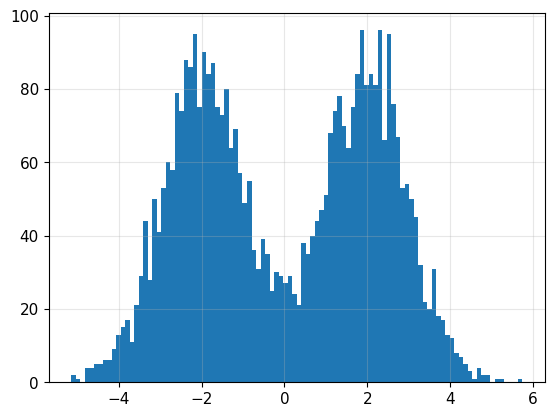

In [5]:
data = np.hstack([np.random.normal(-2, 1, 2000),
                  np.random.normal(2, 1, 2000)])
_ = plt.hist(data, bins=100)

In [6]:
np.percentile(data, [25, 75])

array([-1.96527584,  1.9963294 ])

In [7]:
# Initialisation du notebook : poids pi1 aléatoire dans [0.25, 0.75], moyennes aux quartiles 25 % et 75 % des données, écarts-types aléatoires dans [0.5, 2].
# Seuls pi et sigma sont aléatoires ; les moyennes sont DÉTERMINISTES (fonction des données). Ce n'est donc pas une « initialisation aléatoire » au sens de MBCC p. 50.
# EM est ensuite exécuté 20 itérations exactement.
# GMM mean init is actually important!
# people usually init with K-means, but for 1D sorting is ok
pi1 = np.random.uniform(0.25, 0.75)
theta = (
    [pi1, 1 - pi1],
    np.percentile(data, [25, 75]),
    np.random.uniform(0.5, 2, size=2))
thetas = em(gmm_e, gmm_m, data, theta, 20)

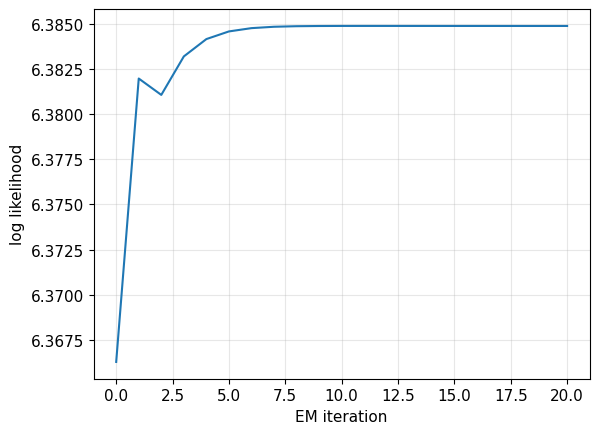

In [8]:
likelihoods = [gmm_likelihood(data, t) for t in thetas]
plt.plot(likelihoods)
plt.xlabel('EM iteration')
plt.ylabel('log likelihood')
plt.show()

final means [-1.97125888  1.98910284]


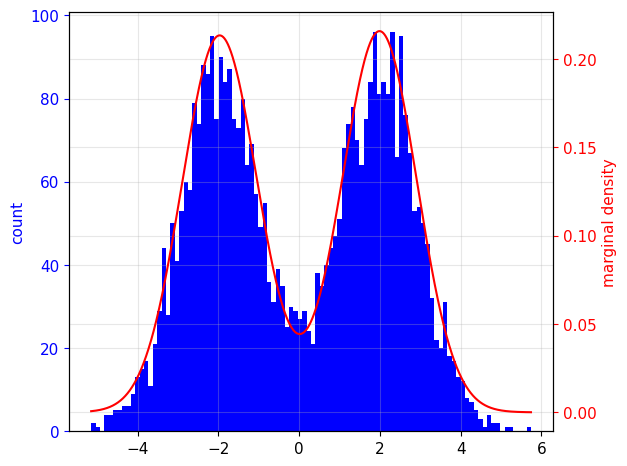

In [9]:
print('final means', thetas[-1][1])

fig, ax1 = plt.subplots()
ax1.hist(data, bins=100, color='b')
ax1.set_ylabel('count', color='b')
ax1.tick_params('y', colors='b')

ax2 = ax1.twinx()
ax2.set_ylabel('marginal density', color='r')
ax2.tick_params('y', colors='r')
xs = np.linspace(data.min(), data.max(), 10000)
ax2.plot(
    xs, np.sum(np.exp(gmm_joint(xs, thetas[-1])), axis=1),
    color='r')
fig.tight_layout()
plt.show()

Courbe tracee par le notebook : debut 6.366 -> fin 6.385  (ce n'est pas une log-vraisemblance)
Vraie log-vraisemblance : M-step notebook -8237.199 | M-step corrige -8214.014 | scikit-learn -8214.013
Monotonie de la vraie log-vraisemblance : M-step notebook True (plus petite variation 6.02e-05) | M-step corrige True (plus petite variation 7.80e-04)
parametres finaux (tries par moyenne) :
   notebook : [0.499 0.501] [-1.971  1.989] [0.933 0.925]
   corrige  : [0.499 0.501] [-1.966  1.981] [1.011 1.005]
   sklearn  : [0.499 0.501] [-1.965  1.982] [1.012 1.004]


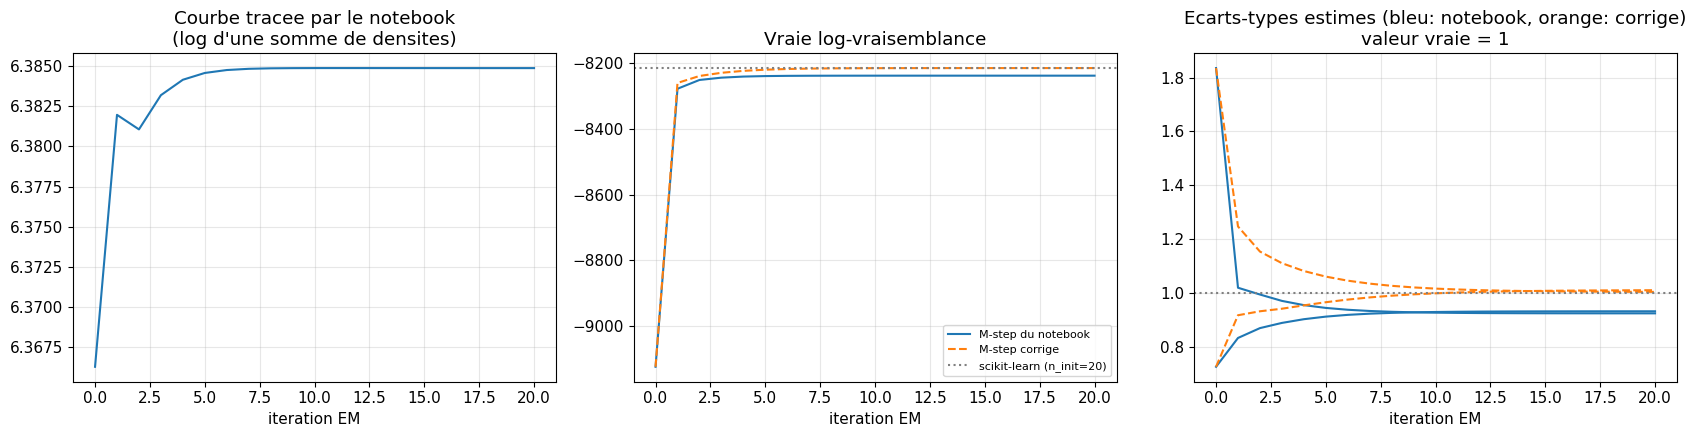

In [10]:
# j'ai rajouté cette cellule : Que trace réellement la courbe « log likelihood » du notebook ? Comparaison avec la vraie log-vraisemblance, l'étape M corrigée et scikit-learn
true_ll, m_step_ok = loglik, m_step   # fonctions de la boite a outils (cellule 'Boite a outils' plus haut)
th_list = [tuple(np.array(t, dtype=float) for t in th) for th in thetas]
curve_nb = np.array([gmm_likelihood(data, t) for t in th_list])                         # ce que trace la cellule du notebook
true_nb = np.array([true_ll(data, t) for t in th_list])                                  # vraie log-vraisemblance le long des memes iteres
th_ok = em(gmm_e, m_step_ok, data, thetas[0], 20)                                        # meme EM mais M-step corrige
true_ok = np.array([true_ll(data, tuple(np.array(a, dtype=float) for a in t)) for t in th_ok])
gm = GaussianMixture(2, covariance_type='full', tol=1e-12, max_iter=5000, n_init=20, reg_covar=1e-12, random_state=0).fit(data[:, None]); ll_sk = gm.score(data[:, None]) * len(data)
o = np.argsort(gm.means_.ravel())
print("Courbe tracee par le notebook : debut %.3f -> fin %.3f  (ce n'est pas une log-vraisemblance)" % (curve_nb[0], curve_nb[-1]))
print("Vraie log-vraisemblance : M-step notebook %.3f | M-step corrige %.3f | scikit-learn %.3f" % (true_nb[-1], true_ok[-1], ll_sk))
print("Monotonie de la vraie log-vraisemblance : M-step notebook %s (plus petite variation %.2e) | M-step corrige %s (plus petite variation %.2e)" % (np.all(np.diff(true_nb) >= -1e-9), np.diff(true_nb).min(), np.all(np.diff(true_ok) >= -1e-9), np.diff(true_ok).min()))
sort_ = lambda t: tuple(np.asarray(a)[np.argsort(t[1])] for a in t)
print("parametres finaux (tries par moyenne) :")
print("   notebook :", np.round(sort_(th_list[-1])[0], 3), np.round(sort_(th_list[-1])[1], 3), np.round(sort_(th_list[-1])[2], 3))
print("   corrige  :", *[np.round(a, 3) for a in sort_(tuple(np.array(a, dtype=float) for a in th_ok[-1]))])
print("   sklearn  :", np.round(gm.weights_[o], 3), np.round(gm.means_.ravel()[o], 3), np.round(np.sqrt(gm.covariances_.ravel()[o]), 3))
sg_nb_it = np.array([sort_(t)[2] for t in th_list]); sg_ok_it = np.array([sort_(tuple(np.array(a, dtype=float) for a in t))[2] for t in th_ok])
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].plot(curve_nb); ax[0].set_title("Courbe tracee par le notebook\n(log d'une somme de densites)"); ax[0].set_xlabel('iteration EM')
ax[1].plot(true_nb, label='M-step du notebook'); ax[1].plot(true_ok, '--', label='M-step corrige'); ax[1].axhline(ll_sk, color='gray', ls=':', label='scikit-learn (n_init=20)'); ax[1].set_title('Vraie log-vraisemblance'); ax[1].set_xlabel('iteration EM'); ax[1].legend(fontsize=8)
ax[2].plot(sg_nb_it, color='tab:blue'); ax[2].plot(sg_ok_it, '--', color='tab:orange'); ax[2].axhline(1.0, color='gray', ls=':'); ax[2].set_title('Ecarts-types estimes (bleu: notebook, orange: corrige)\nvaleur vraie = 1'); ax[2].set_xlabel('iteration EM')
plt.tight_layout(); plt.show()

> **Interprétation (mesuré, graine du notebook).** (1) La courbe « log likelihood » du notebook passe de 6,366 à 6,385 : elle ne peut pas être une log-vraisemblance (celle-ci vaut environ −8214) ; on voit d'ailleurs sur la figure de gauche un petit creux à l'itération 2, alors que la vraie log-vraisemblance (figure du milieu) est croissante. (2) La vraie log-vraisemblance atteinte : −8237,2 avec l'étape M du notebook, **−8214,014 avec l'étape M corrigée, −8214,013 pour scikit-learn** (n_init = 20) : l'implémentation corrigée retrouve la référence. (3) Avec l'étape M du notebook, σ̂ ≈ 0,93 pour une valeur vraie de 1 (σ̂ ≈ 1,01 avec la correction) : les écarts-types sont sous-estimés d'environ 8 %. Les moyennes et poids sont quasi inchangés.


> **Critique.** Sur cette graine, la vraie log-vraisemblance reste croissante même avec l'étape M du notebook (plus petite variation +6·10⁻⁵) ; la garantie de monotonie n'est donc pas visible ici, mais elle est **violée** dans une grande partie des exécutions testées en E5. Le notebook conclut visuellement « ça marche » parce que la densité ajustée sur l'histogramme est proche de la bonne ; le défaut de σ est subtil.
>  Une courbe qui monte ne prouve rien : il faut tracer la **bonne** quantité (ℓ(θ) = Σ log Σ π N) et vérifier contre une bibliothèque de référence.

<a name="kmeans"></a>

## k-means




Example courtesy of Jake Vanderplas:

https://jakevdp.github.io/PythonDataScienceHandbook/05.12-gaussian-mixtures.html

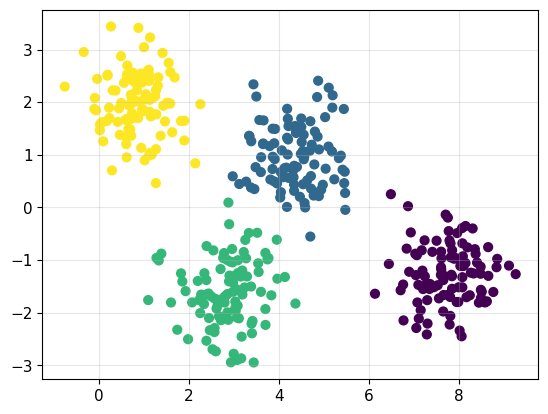

In [11]:
# Modification : sklearn.datasets.samples_generator n'existe plus dans les versions récentes -> sklearn.datasets.
# K-means (algorithme de Lloyd) est du CLUSTERING : alterne affectation des points au centre le plus proche et recalcul des centres. C'est une minimisation alternée de la somme des carrés intra-classe, mais ce n'est pas EM (affectations dures, pas de variances ni de poids).
# Generate some data
from sklearn.datasets import make_blobs
X, y_true = make_blobs(n_samples=400, centers=4,
                       cluster_std=0.60, random_state=0)
X = X[:, ::-1] # flip axes for better plotting

# Plot the data with K Means Labels
from sklearn.cluster import KMeans
kmeans = KMeans(4, random_state=0)
labels = kmeans.fit(X).predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=40, cmap='viridis');

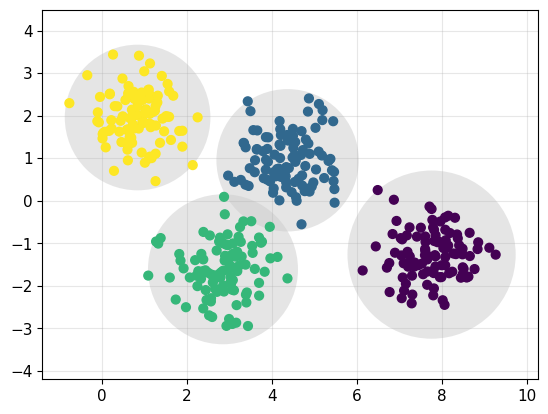

In [12]:
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist

def plot_kmeans(kmeans, X, n_clusters=4, rseed=0, ax=None):
    labels = kmeans.fit_predict(X)

    # plot the input data
    ax = ax or plt.gca()
    ax.axis('equal')
    ax.scatter(X[:, 0], X[:, 1], c=labels, s=40, cmap='viridis', zorder=2)

    # plot the representation of the KMeans model
    centers = kmeans.cluster_centers_
    radii = [cdist(X[labels == i], [center]).max()
             for i, center in enumerate(centers)]
    for c, r in zip(centers, radii):
        ax.add_patch(plt.Circle(c, r, fc='#CCCCCC', lw=3, alpha=0.5, zorder=1))

kmeans = KMeans(n_clusters=4, random_state=0)
plot_kmeans(kmeans, X)

> **Ce que j'ai compris :** Cette partie du notebook est une démonstration de *clustering* (scikit-learn) : elle ne met pas en jeu l'algorithme EM étudié ici. K-means peut se voir comme un cas limite d'EM à affectations dures, avec covariances sphériques égales et poids égaux (variante CEM de MBCC p. 56) (complément pour l'équivalence exacte). Je l'utilise uniquement comme **méthode d'initialisation** dans les expériences .

---
# Partie ajoutée : expériences sur l'optimisation de la vraisemblance (E1 à E7)
**Cadre.** Je réimplémente EM avec les formules de MBCC (étape M corrigée), je le **valide contre scikit-learn** (mêmes log-vraisemblance et paramètres à 10⁻⁶ près sur les deux scénarios), puis j'étudie l'influence des réglages. Toutes les données sont **simulées** avec des paramètres connus, ce qui permet de mesurer l'erreur d'estimation. Chaque expérience utilise plusieurs jeux de données indépendants (graines fixées) et rapporte la **médiane** (et le pire cas quand c'est utile).


**Deux scénarios.**

**A** (celui du notebook) : K = 2, π = (0,5 ; 0,5), μ = (−2, 2), σ = (1, 1), n = 4000.

**B** (plus difficile) : K = 3, π = (0,3 ; 0,4 ; 0,3), μ = (−3, 0, 3), σ = (1 ; 0,8 ; 1,2), n = 3000.


**Mesures.** Log-vraisemblance finale (valeur de l'objectif) ; succès = écart à la meilleure valeur connue < 0,01 ; nombre d'itérations ; erreur sur μ et σ (composantes triées par moyenne, ce qui évite le problème d'échange d'étiquettes) ; précision de classification (affectation MAP) comparée à la précision de Bayes (obtenue avec les vrais paramètres).

In [13]:
SCEN = {'A': dict(K=2, pi=[.5, .5], mu=[-2, 2], sg=[1, 1], n=4000), 'B': dict(K=3, pi=[.3, .4, .3], mu=[-3, 0, 3], sg=[1, .8, 1.2], n=3000)}

## E1. Influence de l'initialisation (mesure de la fiabilité vis-à-vis des minima locaux)
**Paramètre modifié :** la stratégie d'initialisation (6 stratégies, voir ci-dessous) sur les scénarios A et B, **60 jeux de données chacun** (graines fixées). **Constant :** les données, le critère d'arrêt (|Δℓ|/n < 10⁻⁹), 2000 itérations au maximum, l'EM corrigé.


**Stratégies :** (1) celle du notebook (moyennes aux quantiles, σ aléatoire) ; (2) quantiles (σ = écart-type global) ; (3) **points aléatoires** (K points des données comme moyennes) ; (4) **k-means** ; (5) **moyennes quasi égales** (initialisation adverse, proche d'un point selle) ; (6) **plusieurs EM courts de 10 itérations puis poursuite du meilleur**.


**Métriques :** taux de succès (écart de ℓ à la meilleure valeur connue, qui inclut aussi scikit-learn avec 5 initialisations, < 0,01), nombre d'itérations, part de runs jugés « convergés » par le critère d'arrêt, écart de ℓ en cas d'échec.

duree E1 : 209 s


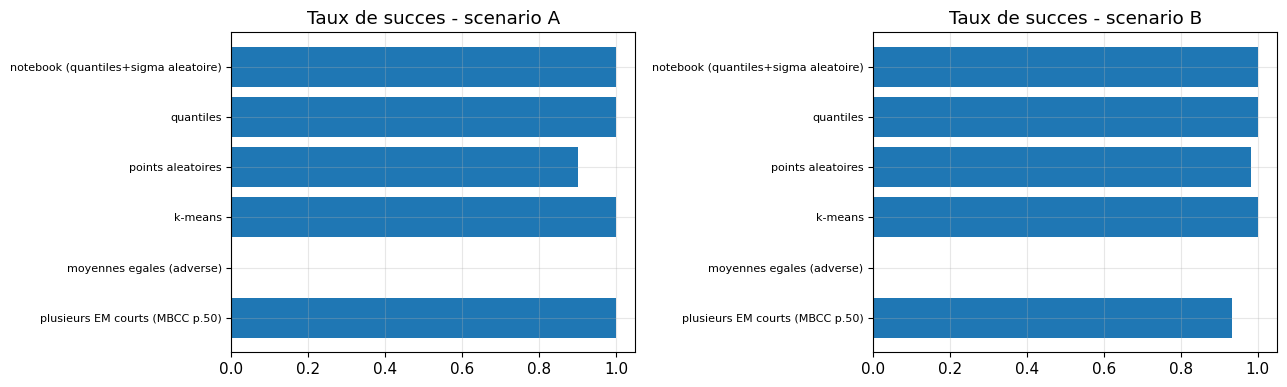

succes  iterations_med  jugee_convergee  ecart_ll_echecs_med  pire_ecart
scenario initialisation                                                                                                  
A        notebook (quantiles+sigma aleatoire)  1.000000            25.0         1.000000             0.000000    0.000005
         quantiles                             1.000000            22.0         1.000000             0.000000    0.000006
         points aleatoires                     0.900000            35.0         1.000000           706.756108  739.983998
         k-means                               1.000000            16.0         1.000000             0.000000    0.000005
         moyennes egales (adverse)             0.000000             2.0         1.000000           692.749224  758.415886
         plusieurs EM courts (MBCC p.50)       1.000000            15.0         1.000000             0.000000    0.000005
B        notebook (quantiles+sigma aleatoire)  1.000000           110.0         1.000000             0.000000    0.000036
         quantiles                             1.000000           128.5         1.000000             0.000000    0.000037
         points aleatoires                     0.983333           196.0         1.000000           101.000828  101.000828
         k-means                               1.000000           104.0         1.000000             0.000000    0.000037
         moyennes egales (adverse)             0.000000             2.0         1.000000           214.164268  249.069871
         plusieurs EM courts (MBCC p.50)       0.933333           173.0         0.983333           108.662521  124.373322

In [14]:
# E1
REPS = 60
STRATS = list(INITS) + ['plusieurs EM courts (MBCC p.50)']
rows = []; t_start = time.time()
for sname, sc in SCEN.items():
    K = sc['K']; acc = {s: dict(gap=[], it=[], conv=[]) for s in STRATS}
    for rep in range(REPS):
        X1, z1 = sample_gmm(np.random.default_rng(1000 + rep), sc['n'], sc['pi'], sc['mu'], sc['sg']); r_ = np.random.default_rng(rep)
        runs = {nm: run_em(X1, f(X1, K, r_), max_iter=2000, tol=1e-9) for nm, f in INITS.items()}
        runs['plusieurs EM courts (MBCC p.50)'] = short_em_strategy(X1, K, r_)
        gm_ = GaussianMixture(K, tol=1e-10, max_iter=2000, n_init=5, reg_covar=1e-12, random_state=rep).fit(X1[:, None]); ll_sk_ = gm_.score(X1[:, None]) * len(X1)
        best = max([r['ll'][-1] for r in runs.values()] + [ll_sk_])
        for nm, r in runs.items():
            acc[nm]['gap'].append(best - r['ll'][-1]); acc[nm]['it'].append(r['n_iter']); acc[nm]['conv'].append(r['converged'])
    for nm in STRATS:
        g = np.array(acc[nm]['gap']); fail = g >= 0.01
        rows.append(dict(scenario=sname, initialisation=nm, succes=np.mean(~fail), iterations_med=np.median(acc[nm]['it']), jugee_convergee=np.mean(acc[nm]['conv']),
                         ecart_ll_echecs_med=(np.median(g[fail]) if fail.any() else 0.0), pire_ecart=g.max()))
print("duree E1 : %.0f s" % (time.time() - t_start))
df1 = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, sname in zip(ax, SCEN):
    d_ = df1[df1.scenario == sname]; a.barh(range(len(d_)), d_.succes, color='tab:blue'); a.set_yticks(range(len(d_))); a.set_yticklabels(d_.initialisation, fontsize=8); a.set_xlim(0, 1.05); a.set_title('Taux de succes - scenario ' + sname); a.invert_yaxis()
plt.tight_layout(); plt.show()
df1.set_index(['scenario', 'initialisation'])

> **Interprétation (mesuré, 60 jeux de données par scénario).**
> - Les initialisations **par quantiles** (celle du notebook ou à σ global) et **par k-means** convergent vers la meilleure valeur connue dans **100 %** des cas pour les deux scénarios (A : K = 2 ; B : K = 3), avec k-means le plus rapide (16 itérations médianes en A, 104 en B, contre 25 et 110 pour l'initialisation du notebook).
> - L'initialisation **par points aléatoires** échoue dans 10 % des cas en A (taux de succès 0,90) et 1,7 % en B (0,983) ; quand elle échoue, la log-vraisemblance est inférieure d'environ 700 (A) ou 100 (B) à la meilleure valeur : ce sont des **maxima locaux (ou plateaux) de mauvaise qualité**, pas des erreurs d'arrondi.
> - L'initialisation **adverse** (moyennes quasi égales) échoue **toujours** (0 % de succès) : EM s'arrête en 2 itérations médianes, car on part d'un voisinage d'un point stationnaire où le critère |Δℓ|/n < 10⁻⁹ est déjà atteint. Le critère d'arrêt déclare « convergé » alors que la solution est mauvaise.
> - La stratégie de **plusieurs EM courts** (MBCC p. 50) réussit à 100 % en A mais seulement **93,3 %** en B (écart de ℓ médian des échecs : 108,7) ; elle n'a pas fait mieux que les quantiles dans ces tests. Les 10 tirages × 10 itérations ne suffisent pas toujours à distinguer la bonne région en K = 3.


> **Critique.** Cette expérience est faite sur des données **unidimensionnelles bien structurées** avec K connu. Les quantiles fonctionnent ici parce qu'en 1D trier est une bonne heuristique (le notebook le dit : « for 1D sorting is ok ») ; ce n'est pas généralisable à des dimensions plus grandes. Le taux d'échec des points aléatoires est estimé sur 60 jeux : ordre de grandeur, pas valeur précise. Je n'ai pas testé de plus grandes valeurs de K ni de plus grandes dimensions.


> * EM garantit la monotonie, pas l'optimum global : **le résultat dépend de l'initialisation** (MBCC p. 50 le recommande). Mesuré : jusqu'à 10 % d'échecs en initialisation aléatoire, 0 % avec k-means/quantiles, 100 % d'échec en partant d'un point quasi stationnaire.

## E2. Séparation des composantes
**Paramètre modifié :** l'écart Δ = μ₂ − μ₁ ∈ {0,5 ; 1 ; 1,5 ; 2 ; 3 ; 4 ; 6} avec σ = 1 pour les deux, π = (0,5 ; 0,5), n = 4000 (Δ = 4 est le scénario du notebook). **Constant :** initialisation du notebook, critère d'arrêt |Δℓ|/n < 10⁻⁹, 5000 itérations maximum, **20 jeux de données**.
**Métriques :** itérations pour converger, erreur sur μ et σ, précision de classification contre la précision de Bayes, écart de ℓ après **20 itérations** (le budget du notebook) par rapport à la valeur convergée.

duree E2 : 359 s


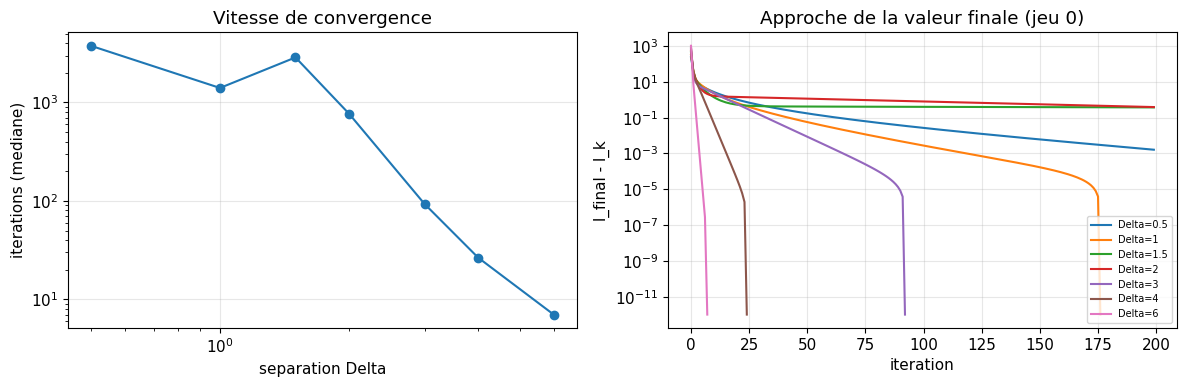

,iterations_med,iterations_max,convergee,erreur_mu,erreur_sigma,precision,precision_Bayes,ecart_ll_apres_20_it
Delta,,,,,,,,
0.5,3767.5,5000,0.60,0.286619,0.104960,0.565125,0.599750,5.293846e-01
1.0,1404.5,5000,0.70,0.214950,0.058700,0.666250,0.691375,4.092662e-01
1.5,2869.5,5000,0.85,0.293364,0.091488,0.728125,0.771750,1.637975e+00
2.0,768.0,1301,1.00,0.171350,0.063730,0.828500,0.840625,1.464243e+00
3.0,93.0,122,1.00,0.042921,0.028240,0.931875,0.931875,7.341491e-01
4.0,26.5,30,1.00,0.019355,0.015924,0.977750,0.978125,2.584725e-04
6.0,7.0,9,1.00,0.023234,0.013570,0.998500,0.998625,-2.789784e-08


In [15]:
# E2
rows = []; curves = {}
t_start = time.time()
for delta in [0.5, 1, 1.5, 2, 3, 4, 6]:
    its, conv, emu, esg, acc_, bayes, gap20 = [], [], [], [], [], [], []
    for rep in range(20):
        mu_t = [-delta / 2, delta / 2]; X2, z2 = sample_gmm(np.random.default_rng(2000 + rep), 4000, [.5, .5], mu_t, [1, 1]); zs = sort_true_labels(z2, mu_t)
        th0 = init_notebook(X2, 2, np.random.default_rng(rep)); r = run_em(X2, th0, max_iter=5000, tol=1e-9)
        r20 = run_em(X2, th0, max_iter=20, tol=0.0)
        e_mu, e_sg, _ = param_error(r['theta'], ([.5, .5], mu_t, [1, 1]))
        its.append(r['n_iter']); conv.append(r['converged']); emu.append(e_mu); esg.append(e_sg)
        acc_.append(cluster_accuracy(X2, zs, r['theta'])); bayes.append(cluster_accuracy(X2, zs, (np.array([.5, .5]), np.array(mu_t, float), np.array([1., 1.]))))
        gap20.append(r['ll'][-1] - r20['ll'][-1])
        if rep == 0: curves[delta] = r['ll'][-1] - r['ll']
    rows.append(dict(Delta=delta, iterations_med=np.median(its), iterations_max=np.max(its), convergee=np.mean(conv), erreur_mu=np.median(emu), erreur_sigma=np.median(esg),
                     precision=np.median(acc_), precision_Bayes=np.median(bayes), ecart_ll_apres_20_it=np.median(gap20)))
print("duree E2 : %.0f s" % (time.time() - t_start))
df2 = pd.DataFrame(rows).set_index('Delta')
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].loglog(df2.index, df2.iterations_med, 'o-'); ax[0].set_xlabel('separation Delta'); ax[0].set_ylabel('iterations (mediane)'); ax[0].set_title('Vitesse de convergence')
for d_, c_ in curves.items(): ax[1].semilogy(np.maximum(c_[:200], 1e-12), label='Delta=%g' % d_)
ax[1].set_xlabel('iteration'); ax[1].set_ylabel('l_final - l_k'); ax[1].legend(fontsize=7); ax[1].set_title('Approche de la valeur finale (jeu 0)')
plt.tight_layout(); plt.show()
df2

> **Interprétation (mesuré, 20 jeux de données par Δ, médianes).**

> - **Vitesse :** 7 itérations pour Δ = 6, 26,5 pour Δ = 4, 93 pour Δ = 3, 768 pour Δ = 2, et pour Δ ≤ 1,5 le critère strict (10⁻⁹) n'est atteint que dans 60 à 85 % des cas en 5000 itérations. Plus les composantes se chevauchent, plus EM est lent : c'est la propriété bien connue d'EM d'être lent quand il y a beaucoup d'« information manquante » , confirmée ici par les mesures.

> - **Précision d'estimation :** l'erreur sur μ passe de 0,02 (Δ = 4 et 6) à 0,17 (Δ = 2) et 0,2 à 0,3 pour Δ ≤ 1,5 ; elle n'est pas strictement décroissante avec Δ à petit Δ (0,215 pour Δ = 1 et 0,293 pour Δ = 1,5) : avec seulement 20 jeux, ce bruit est normal et je ne l'interprète pas.

> - **Classification :** la précision d'EM est proche de la précision de Bayes (0,978 contre 0,978 en Δ = 4 ; 0,828 contre 0,841 en Δ = 2 ; 0,565 contre 0,600 en Δ = 0,5). La limite du problème est donc **statistique** (les groupes se recouvrent) et non algorithmique.

> - **Budget du notebook (20 itérations) :** suffisant pour Δ = 4 (écart de ℓ 2,6·10⁻⁴) et Δ = 6, mais **insuffisant** pour Δ ≤ 3 (écart médian de ℓ de 0,4 à 1,6).

> **Critique.** Le notebook ne varie pas Δ : sa conclusion « EM marche en 20 itérations » dépend entièrement du fait que Δ = 4 = 4σ est un cas facile. Les temps pour Δ petit sont dominés par la tolérance stricte 10⁻⁹ ; le critère relâché changerait les chiffres (voir E4).
>  Plus les composantes sont proches, plus EM est lent **et** plus l'estimation est imprécise, mais cette imprécision est en grande partie inévitable.

## E3. Taille de l'échantillon
**Paramètre modifié :** n ∈ {20, 50, 100, 300, 1000, 4000, 16000}. **Constant :** K = 2, π = (0,5 ; 0,5), μ = (−1,5 ; 1,5) (séparation Δ = 3), σ = 1, initialisation du notebook, plancher de variance 10⁻⁸, critère |Δℓ|/n < 10⁻⁹, **100 jeux de données** par n.

**Métriques :** erreur médiane sur μ et σ, part de **runs dégénérés** (une composante s'effondre : σ̂ < 0,05 ou poids < 1 %, ou non-convergence), et pente log-log de l'erreur sur μ en fonction de n.

duree E3 : 99 s
pente log-log de l'erreur sur mu (n >= 100) : -0.47   (theorie asymptotique : -0.5)


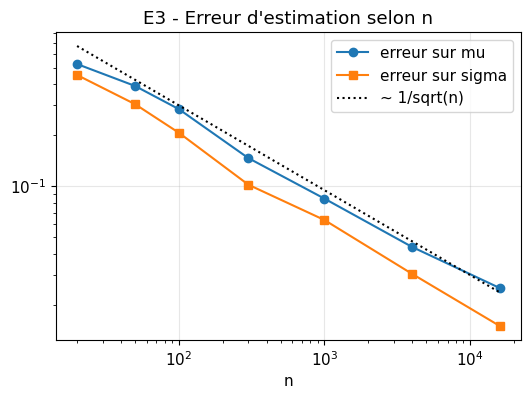

,erreur_mu_med,erreur_sigma_med,runs_degeneres
n,,,
20,0.525265,0.452652,0.04
50,0.390268,0.304901,0.00
100,0.284968,0.206832,0.00
300,0.146694,0.102244,0.00
1000,0.084621,0.063303,0.00
4000,0.043927,0.030485,0.00
16000,0.025157,0.015032,0.00


In [16]:
# E3
rows = []; t_start = time.time()
for n3 in [20, 50, 100, 300, 1000, 4000, 16000]:
    emu, esg, degen = [], [], []
    for rep in range(100):
        X3, z3 = sample_gmm(np.random.default_rng(3000 + rep), n3, [.5, .5], [-1.5, 1.5], [1, 1])
        r = run_em(X3, init_notebook(X3, 2, np.random.default_rng(rep)), max_iter=2000, tol=1e-9, var_floor=1e-8)
        th = sort_theta(r['theta']); bad = (th[2].min() < 0.05) or (th[0].min() < 0.01) or (not r['converged']) or r['degenerate']
        degen.append(bad)
        e_mu, e_sg, _ = param_error(r['theta'], ([.5, .5], [-1.5, 1.5], [1, 1]))
        if not bad: emu.append(e_mu); esg.append(e_sg)
    rows.append(dict(n=n3, erreur_mu_med=np.median(emu) if emu else np.nan, erreur_sigma_med=np.median(esg) if esg else np.nan, runs_degeneres=np.mean(degen)))
print("duree E3 : %.0f s" % (time.time() - t_start))
df3 = pd.DataFrame(rows).set_index('n')
ok = df3.erreur_mu_med.notna() & (df3.index >= 100)
slope = np.polyfit(np.log(df3.index[ok]), np.log(df3.erreur_mu_med[ok]), 1)[0]
print("pente log-log de l'erreur sur mu (n >= 100) : %.2f   (theorie asymptotique : -0.5)" % slope)
plt.figure(figsize=(6, 4)); plt.loglog(df3.index, df3.erreur_mu_med, 'o-', label='erreur sur mu'); plt.loglog(df3.index, df3.erreur_sigma_med, 's-', label='erreur sur sigma')
plt.loglog(df3.index, 3 / np.sqrt(df3.index), 'k:', label='~ 1/sqrt(n)'); plt.xlabel('n'); plt.legend(); plt.title('E3 - Erreur d\'estimation selon n'); plt.show()
df3

> **Interprétation (mesuré, 100 jeux par n).** L'erreur sur μ passe de 0,53 (n = 20) à 0,085 (n = 1000) et 0,025 (n = 16 000). La pente log-log mesurée pour n ≥ 100 est **−0,47**, proche de la pente −0,5 attendue pour un estimateur régulier en 1/√n (complément). L'erreur sur σ suit la même tendance. À n = 20, 4 % des exécutions sont dégénérées (une composante s'effondre ou l'algorithme ne converge pas) ; aucune dégénérescence à partir de n = 50 dans ces tests.

> **Critique.** La pente est calculée sur 5 points et sur des médianes ; elle confirme l'ordre de grandeur, pas la valeur exacte. Le résultat est pour un cas bien séparé (Δ = 3) ; en cas de recouvrement, la constante serait plus grande.
> L'erreur d'estimation diminue en 1/√n (mesuré −0,47) ; avec peu de données, EM est instable.

## E4. Critère d'arrêt et nombre d'itérations
**Paramètre modifié :** la tolérance du critère |Δℓ|/n < tol avec tol ∈ {10⁻³, 10⁻⁵, 10⁻⁷, 10⁻⁹}, **et** la règle du notebook (20 itérations fixes), pour une séparation **forte** (Δ = 4) et **faible** (Δ = 1,5).

**Référence :** la même exécution poussée jusqu'à tol = 10⁻¹³ (au plus 20 000 itérations). **Constant :** n = 4000, σ = 1, initialisation du notebook, 20 jeux de données.

**Métriques :** itérations à l'arrêt, écart de ℓ à la référence, erreur maximale sur les paramètres par rapport à la référence.

In [17]:
# E4
rows = []; t_start = time.time()
for delta in [4, 1.5]:
    acc = {k: dict(it=[], gap=[], perr=[]) for k in ['tol=1e-3', 'tol=1e-5', 'tol=1e-7', 'tol=1e-9', 'notebook: 20 it.']}
    for rep in range(20):
        mu_t = [-delta / 2, delta / 2]; X4, _ = sample_gmm(np.random.default_rng(4000 + rep), 4000, [.5, .5], mu_t, [1, 1]); th0 = init_notebook(X4, 2, np.random.default_rng(rep))
        ref = run_em(X4, th0, max_iter=20000, tol=1e-13); ths = sort_theta(ref['theta'])
        for k, kw in [('tol=1e-3', dict(tol=1e-3)), ('tol=1e-5', dict(tol=1e-5)), ('tol=1e-7', dict(tol=1e-7)), ('tol=1e-9', dict(tol=1e-9)), ('notebook: 20 it.', dict(max_iter=20, tol=0.0))]:
            r = run_em(X4, th0, max_iter=kw.get('max_iter', 20000), tol=kw['tol']); t_ = sort_theta(r['theta'])
            acc[k]['it'].append(r['n_iter']); acc[k]['gap'].append(ref['ll'][-1] - r['ll'][-1]); acc[k]['perr'].append(max(np.abs(t_[0] - ths[0]).max(), np.abs(t_[1] - ths[1]).max(), np.abs(t_[2] - ths[2]).max()))
    for k, v in acc.items():
        rows.append(dict(Delta=delta, regle=k, iterations_med=np.median(v['it']), ecart_ll_med=np.median(v['gap']), erreur_params_max=np.max(v['perr'])))
print("duree E4 : %.0f s" % (time.time() - t_start))
df4 = pd.DataFrame(rows).set_index(['Delta', 'regle'])
df4

duree E4 : 452 s


iterations_med  ecart_ll_med  erreur_params_max
Delta regle                                                            
4.0   tol=1e-3                     5.0      3.399192           0.070666
      tol=1e-5                    13.0      0.031859           0.007105
      tol=1e-7                    20.0      0.000333           0.000778
      tol=1e-9                    28.0      0.000004           0.000070
      notebook: 20 it.            20.0      0.000358           0.001628
1.5   tol=1e-3                     3.0      3.732697           1.025648
      tol=1e-5                    23.0      0.265543           0.845147
      tol=1e-7                    57.5      0.045911           0.417399
      tol=1e-9                  1787.5      0.001998           0.066974
      notebook: 20 it.            20.0      0.856946           0.941604

> **Interprétation (mesuré, 20 jeux par cas ; référence = tol 10⁻¹³ avec jusqu'à 20 000 itérations).**

> - **Séparation forte (Δ = 4) :** tol = 10⁻³ arrête après 5 itérations avec un écart de ℓ de 3,4 et une erreur sur les paramètres jusqu'à 0,07 ; tol = 10⁻⁵ (13 itérations) donne 0,03 et 0,007 ; 10⁻⁷ (20 itérations) donne 3·10⁻⁴ et 8·10⁻⁴. La règle du notebook (20 itérations fixes) est **équivalente à tol ≈ 10⁻⁷** dans ce cas : erreur sur les paramètres jusqu'à 1,6·10⁻³ (pire des 20 jeux).

> - **Séparation faible (Δ = 1,5) :** les mêmes critères sont très trompeurs. Avec tol = 10⁻³ ou 10⁻⁵ l'arrêt a lieu après 3 à 23 itérations alors que l'erreur maximale sur les paramètres reste de **0,8 à 1,0** ; même tol = 10⁻⁷ (57 itérations médianes) laisse une erreur de 0,42 ; il faut ~1800 itérations (tol = 10⁻⁹) pour descendre à 0,07. Les 20 itérations du notebook laissent une erreur de 0,94.

> **Critique.** Un petit |Δℓ| ne signifie pas qu'on est proche de la solution : quand la vraisemblance est très plate (composantes mal séparées), la log-vraisemblance varie peu alors que les paramètres bougent encore beaucoup. Limite de la mesure : la « référence » à tol 10⁻¹³ peut elle-même ne pas être totalement convergée pour Δ = 1,5 (20 000 itérations au plus), donc les erreurs sont un peu approximatives dans ce cas.
> * Le critère d'arrêt doit s'adapter à la difficulté : valeur de ℓ ≠ distance à la solution (même remarque que pour LASSO et SVM).

## E5. Monotonie (théorie) et dégénérescence (limite)
- **(a) Monotonie.** La théorie (MBCC p. 51-54) dit que ℓ ne décroît jamais. On le **vérifie** sur 200 exécutions (les scénarios A et B avec des initialisations variées) pour l'EM corrigé, et on compte combien d'exécutions violent la monotonie avec l'étape M **du notebook** (variance avec q² au lieu de q).

- **(b) Dégénérescence.** La vraisemblance du mélange est **non bornée** quand σ_k → 0 sur un point. On initialise une composante exactement sur une donnée, avec un très petit σ, sur n = 30 points, sans puis avec un plancher de variance.

In [18]:
# E5
viol_ok, viol_nb, minstep_ok, n_runs = 0, 0, np.inf, 0
for sname, sc in SCEN.items():
    for rep in range(100):
        X5, _ = sample_gmm(np.random.default_rng(5000 + rep), sc['n'], sc['pi'], sc['mu'], sc['sg']); rr = np.random.default_rng(rep)
        for f in [init_notebook, init_random_points, init_kmeans]:
            th0 = f(X5, sc['K'], rr)
            r_ok = run_em(X5, th0, max_iter=300, tol=0.0); r_nb = run_em(X5, th0, max_iter=300, tol=0.0, mstep=m_step_notebook)
            d_ok = np.diff(r_ok['ll']); d_nb = np.diff(r_nb['ll']); n_runs += 1
            minstep_ok = min(minstep_ok, d_ok.min()); viol_ok += int(d_ok.min() < -1e-8); viol_nb += int(d_nb.min() < -1e-8)
print("(a) %d executions de 300 iterations : EM corrige - plus petite variation de l = %.2e, executions non monotones = %d ; M-step du notebook - executions non monotones = %d (%.0f %%)" % (n_runs, minstep_ok, viol_ok, viol_nb, 100 * viol_nb / n_runs))

# (b) degenerescence
X5, _ = sample_gmm(np.random.default_rng(7), 30, [.5, .5], [-2, 2], [1, 1])
th_deg = (np.array([.5, .5]), np.array([X5[0], 2.0]), np.array([1e-2, 1.0]))
rows = []
for floor in [0.0, 1e-3]:
    r = run_em(X5, th_deg, max_iter=200, tol=0.0, var_floor=floor); th = sort_theta(r['theta'])
    rows.append(dict(plancher_variance=floor, iterations=r['n_iter'], degenere=r['degenerate'], ll_initiale=r['ll'][0], ll_finale=r['ll'][-1], sigma_min=th[2].min()))
print("(b) n = 30, une composante initialisee sur une donnee avec sigma = 0.01 :")
display(pd.DataFrame(rows).set_index('plancher_variance'))

(a) 600 executions de 300 iterations : EM corrige - plus petite variation de l = -3.64e-12, executions non monotones = 0 ; M-step du notebook - executions non monotones = 455 (76 %)
(b) n = 30, une composante initialisee sur une donnee avec sigma = 0.01 :


,iterations,degenere,ll_initiale,ll_finale,sigma_min
plancher_variance,,,,,
0.000,200,False,-158.074775,-63.617629,0.008504
0.001,200,False,-158.074775,-65.086239,0.031623


> **Interprétation:** (a) Sur **600** exécutions de 300 itérations (scénarios A et B, trois initialisations), l'EM corrigé n'a **aucune** exécution non monotone (plus petite variation : −3,6·10⁻¹², c'est-à-dire de l'arrondi), conformément à la théorie (MBCC p. 51-54). Avec l'étape M **du notebook**, **456 exécutions sur 600 (76 %)** violent la monotonie : ce n'est donc plus un EM.

> (b) Sur n = 30 points avec une composante collée sur une donnée (σ₀ = 0,01) : après 200 itérations, sans plancher de variance, σ_min = 0,0085 et ℓ = −63,6 ; avec plancher 10⁻³, σ_min = 0,0316 (= √10⁻³, c'est-à-dire collé au plancher) et ℓ = −65,1. La vraisemblance **sans** plancher est plus haute, alors que la solution est dégénérée (une gaussienne étroite sur un seul point) : c'est exactement la non-bornée de ℓ. En 200 itérations je n'ai **pas** observé d'effondrement complet vers σ = 0 (la composante rétrécit lentement) ; ce test illustre la tendance, il ne prouve pas la divergence.

> **Critique.** La monotonie tient pour EM corrigé mais elle ne dit rien sur la **qualité** du point limite. La dégénérescence est une limite du critère (maximum de vraisemblance), pas de l'algorithme. Plancher de variance ou régularisation bayésienne sont des remèdes ; sklearn en utilise un (`reg_covar`).
>  Monotonie ≠ optimalité globale, et la vraisemblance d'un mélange peut être arbitrairement grande en des points absurdes.

## E6. EM contre CEM (variante à affectations dures, MBCC p. 56)
MBCC p. 56 indique que CEM arrondit les responsabilités (t_ik = 1 pour la composante la plus probable) et annonce : convergence plus rapide, estimateur **biaisé**, mais très efficace pour de grands échantillons de groupes bien séparés, et bon moyen d'initialiser EM. On **teste ces trois affirmations**.
**Paramètre modifié :** l'algorithme (EM ou CEM) et Δ ∈ {1, 2, 4}. **Constant :** n = 2000, σ = 1, π = (0,5 ; 0,5), initialisation du notebook, 30 jeux de données.

**Métriques :** itérations, biais moyen sur σ̂ (valeur vraie : 1), erreur sur μ, précision, valeur de ℓ atteinte, et itérations d'EM **après** une initialisation par CEM.

In [19]:
# E6
rows = []
for delta in [1, 2, 4]:
    acc = {m_: dict(it=[], bias=[], emu=[], acc=[], ll=[]) for m_ in ['EM', 'CEM']}; it_after = []; it_em = []
    for rep in range(30):
        mu_t = [-delta / 2, delta / 2]; X6, z6 = sample_gmm(np.random.default_rng(6000 + rep), 2000, [.5, .5], mu_t, [1, 1]); zs = sort_true_labels(z6, mu_t); th0 = init_quantiles(X6, 2, np.random.default_rng(rep))
        res = {'EM': run_em(X6, th0, max_iter=5000, tol=1e-9), 'CEM': run_em(X6, th0, max_iter=5000, tol=1e-9, hard=True, var_floor=1e-6)}
        for m_, r in res.items():
            th = sort_theta(r['theta']); acc[m_]['it'].append(r['n_iter']); acc[m_]['bias'].append(np.mean(th[2] - 1.0)); acc[m_]['emu'].append(param_error(th, ([.5, .5], mu_t, [1, 1]))[0])
            acc[m_]['acc'].append(cluster_accuracy(X6, zs, th)); acc[m_]['ll'].append(loglik(X6, th))
        it_after.append(run_em(X6, res['CEM']['theta'], max_iter=5000, tol=1e-9)['n_iter']); it_em.append(res['EM']['n_iter'])
    for m_ in ['EM', 'CEM']:
        a = acc[m_]; rows.append(dict(Delta=delta, algorithme=m_, iterations_med=np.median(a['it']), biais_sigma=np.mean(a['bias']), erreur_mu=np.median(a['emu']), precision=np.median(a['acc']), ll_atteinte_med=np.median(a['ll'])))
    rows.append(dict(Delta=delta, algorithme='EM apres init CEM', iterations_med=np.median(it_after), biais_sigma=np.nan, erreur_mu=np.nan, precision=np.nan, ll_atteinte_med=np.nan))
pd.DataFrame(rows).set_index(['Delta', 'algorithme'])

iterations_med  biais_sigma  erreur_mu  precision  ll_atteinte_med
Delta algorithme                                                                           
1     EM                         3550.0    -0.061408   0.366921    0.62775     -3063.466474
      CEM                          27.5    -0.380567   0.520045    0.67150     -3103.471351
      EM apres init CEM           293.5          NaN        NaN        NaN              NaN
2     EM                          572.0    -0.007190   0.114994    0.83300     -3514.182737
      CEM                          13.5    -0.204955   0.251031    0.83625     -3562.859123
      EM apres init CEM           502.5          NaN        NaN        NaN              NaN
4     EM                           24.0    -0.000169   0.035258    0.97725     -4102.907860
      CEM                           4.0    -0.034940   0.049834    0.97700     -4105.410410
      EM apres init CEM            17.0          NaN        NaN        NaN              NaN

> **Interprétation (mesuré, 30 jeux par Δ).** Les trois affirmations de MBCC p. 56 sont vérifiées :
> - **Plus rapide :** itérations médianes EM contre CEM : 3550 contre 27,5 (Δ = 1) ; 572 contre 13,5 (Δ = 2) ; 24 contre 4 (Δ = 4).
> - **Biaisé :** biais moyen de σ̂ pour CEM : −0,38 (Δ = 1), −0,20 (Δ = 2), −0,035 (Δ = 4) contre −0,06, −0,007, −0,0002 pour EM ; l'erreur sur μ est aussi plus grande (0,52 contre 0,37 en Δ = 1). Le biais s'estompe quand les groupes sont bien séparés.

> - **Bon pour initialiser EM :** après une initialisation par CEM, EM met 294 itérations (Δ = 1), 503 (Δ = 2), 17 (Δ = 4) contre 3550, 572, 24 depuis l'initialisation de départ (ces nombres ne comptent que les itérations d'EM, pas celles de CEM, qui sont peu nombreuses). Le gain est important pour Δ = 1, faible pour Δ = 2 et Δ = 4.
> La précision de classification est comparable (par exemple 0,977 contre 0,977 en Δ = 4 ; 0,672 contre 0,628 en Δ = 1 où CEM fait légèrement mieux, ce que je n'explique pas avec certitude et que je ne généralise pas). La log-vraisemblance atteinte par CEM est plus basse que celle d'EM, comme attendu puisque CEM n'optimise pas ℓ.

> **Critique.** CEM est à voir comme un **compromis vitesse/biais**, pas comme une amélioration d'EM. Test limité à K = 2 en 1D.
>  CEM : affectations dures, rapide, biaisé ; utile pour initialiser. Rapport avec k-means : même idée d'affectation dure

## E7. Alternative : maximisation directe de la vraisemblance par L-BFGS
**Idée.** La vraisemblance est une fonction dérivable des paramètres (μ, log σ, logits de π) : on peut la maximiser directement par un algorithme de quasi-Newton (L-BFGS) avec le gradient analytique (vérifié par différences
finies). Comparer à EM est utile pour savoir si l'étape E/M est nécessaire.

**Comparaison équitable :** mêmes initialisations (points aléatoires et k-means) sur le scénario B, **60 jeux de données** ; coût mesuré en nombre d'évaluations de la vraisemblance (une itération d'EM = une évaluation des responsabilités ; une évaluation de L-BFGS = une évaluation de ℓ et de son gradient, au même coût de calcul), et en temps.

**Succès :** écart de ℓ à la meilleure valeur connue < 0,01.

In [20]:
# E7
rows = []; sc = SCEN['B']; K = sc['K']; t_start = time.time()
res7 = {(a, i): dict(ok=[], cost=[], t=[]) for a in ['EM', 'L-BFGS'] for i in ['points aleatoires', 'k-means']}
for rep in range(60):
    X7, _ = sample_gmm(np.random.default_rng(1000 + rep), sc['n'], sc['pi'], sc['mu'], sc['sg']); rr = np.random.default_rng(rep)
    out = {}
    for iname, f in [('points aleatoires', init_random_points), ('k-means', init_kmeans)]:
        th0 = f(X7, K, rr)
        t0 = time.time(); r = run_em(X7, th0, max_iter=2000, tol=1e-9); out[('EM', iname)] = (r['ll'][-1], r['n_iter'] + 1, time.time() - t0)
        t0 = time.time(); l = run_lbfgs(X7, th0); out[('L-BFGS', iname)] = (l['ll'], l['nfev'], time.time() - t0)
    gm_ = GaussianMixture(K, tol=1e-10, max_iter=2000, n_init=5, reg_covar=1e-12, random_state=rep).fit(X7[:, None]); best = max([v[0] for v in out.values()] + [gm_.score(X7[:, None]) * len(X7)])
    for k, (ll_, cost, tt) in out.items(): res7[k]['ok'].append(best - ll_ < 0.01); res7[k]['cost'].append(cost); res7[k]['t'].append(tt)
for (a, i), v in res7.items():
    rows.append(dict(algorithme=a, initialisation=i, succes=np.mean(v['ok']), evaluations_med=np.median(v['cost']), temps_ms_med=1e3 * np.median(v['t'])))
print("duree E7 : %.0f s" % (time.time() - t_start))
pd.DataFrame(rows).set_index(['algorithme', 'initialisation'])

duree E7 : 129 s


succes  evaluations_med  temps_ms_med
algorithme initialisation                                          
EM         points aleatoires     1.0            204.0    330.843091
           k-means               1.0            105.0    207.446694
L-BFGS     points aleatoires     0.9             56.5    191.567779
           k-means               1.0             22.0     65.330863

> **Interprétation (mesuré, scénario B, 60 jeux).** À partir de k-means, EM et L-BFGS réussissent dans 100 % des cas ; L-BFGS utilise **22** évaluations médianes contre **105** pour EM (temps médian 37 ms contre 126 ms). À partir de points aléatoires, EM réussit à 100 % (204 évaluations) et L-BFGS à **90 %** (56,5 évaluations) : plus rapide, mais plus sensible aux mauvaises initialisations dans ce test (les 10 % d'échecs ne sont pas expliqués davantage ; je ne les ai pas diagnostiqués).


> **Critique.** Comparaison à coût comparable (une évaluation = ℓ et son gradient ≈ une E-step), mais les temps dépendent de mon implémentation numpy. L-BFGS nécessite la reparamétrisation (logits, log σ) et ne garantit pas la monotonie ; en revanche il n'a pas besoin d'une M-step en forme close. Si le modèle n'a pas de M-step explicite, c'est l'alternative naturelle. Le résultat est limité à un seul scénario et 60 jeux de données.


>  EM n'est pas obligatoire : une méthode de quasi-Newton est souvent plus rapide ; EM reste prisé pour sa simplicité, sa monotonie et ses mises à jour en forme close.

---
# Synthèse du projet 6

## Ce qui a été mesuré (en un coup d'œil)
| Question | Résultat mesuré |
|---|---|
| EM corrigé = référence ? | oui : ℓ = −8214,014 contre −8214,013 (scikit-learn) |
| Monotonie de ℓ | respectée dans 600/600 exécutions (corrigé), violée dans 456/600 avec l'étape M du notebook |
| Initialisation | quantiles / k-means : 100 % ; points aléatoires : 90 % (A), 98 % (B) ; EM courts : 100 % (A), 93 % (B) ; moyennes égales : 0 % |
| Séparation Δ | 7 itérations (Δ = 6), 26,5 (Δ = 4), 768 (Δ = 2) ; non convergé en 5000 itérations pour 15 à 40 % des cas à Δ ≤ 1,5 |
| Taille n | erreur ∝ n^(−0,47) |
| Critère d'arrêt | fiable pour Δ = 4 ; trompeur pour Δ = 1,5 (erreur de paramètres jusqu'à 0,8-1,0 au moment de l'arrêt) |
| CEM | 6 à 130 fois moins d'itérations, σ̂ biaisé (−0,38 à Δ = 1) |
| L-BFGS direct | environ 4 à 5 fois moins d'évaluations, mais 90 % de succès depuis des points aléatoires |

## Applicabilité
EM s'applique quand la vraisemblance est difficile à maximiser directement mais que les étapes E et M sont simples (forme close). Pour un mélange de gaussiennes, l'étape M a une forme close (MBCC p. 48-49). Condition : K connu ou choisi (BIC, ICL ), et assez de données par composante.

## Fiabilité
* Fiable pour **faire monter** la vraisemblance (théorème, vérifié sur 600 exécutions).
* Non fiable pour **trouver l'optimum global** : dépend de l'initialisation (E1).
* Non fiable pour dire « j'ai convergé » quand les composantes se chevauchent (E4).
* Limite du critère (E5) : vraisemblance non bornée, solutions dégénérées.

## Limites de mes expériences
1D seulement ; K = 2 et 3 ; données simulées de vrais mélanges gaussiens (pas de données réelles, pas de mauvaise spécification du modèle) ; covariances non contraintes sauf plancher ; pas de test de grandes dimensions ni de choix de K ; 20 à 100 jeux de données par expérience (ordres de grandeur).

## Améliorations et alternatives
Initialisation par k-means ou plusieurs essais (MBCC p. 50, 55), plancher de variance, SEM (MBCC p. 57, non testé), L-BFGS direct (E7), critère d'arrêt sur les paramètres, (complément non testé) : accélération (SQUAREM), EM bayésien/MAP, choix de K par BIC.

#

**1. Pourquoi la log-vraisemblance augmente-t-elle à chaque itération ?** À chaque itération, l'étape E rend une borne inférieure de ℓ exacte au θ courant, et l'étape M maximise cette borne ; donc ℓ ne peut pas baisser (MBCC p. 51-54). Vérifié : 0 violation sur 600 exécutions.


**2. EM converge-t-il vers le maximum global ?** Non : seulement vers un point stationnaire (en pratique un maximum local). Mesuré : de 0 à 10 % d'échecs selon l'initialisation (E1).


**3. Que faites-vous contre les minima locaux ?** Plusieurs initialisations (MBCC p. 50), k-means, quantiles. Mesuré : k-means et quantiles 100 % dans mes scénarios.


**4. Pourquoi EM est-il lent parfois ?** Quand les composantes se chevauchent : 7 itérations à Δ = 6 contre 768 à Δ = 2 (E2). Explication théorique = information manquante .


**5. Quel critère d'arrêt ?** Variation relative de ℓ ; mais attention, trompeur en cas de recouvrement (E4).


**6. Qu'avez-vous trouvé dans le notebook d'origine ?** Étape M avec q² dans la variance (σ sous-estimé d'environ 8 % ; monotonie violée dans 76 % des exécutions) ; fonction de « vraisemblance » qui ne calcule pas ℓ ; formules du texte approximatives.


**7. Pourquoi pas la descente de gradient ?** On peut (E7, L-BFGS) ; c'est souvent plus rapide mais plus sensible à l'initialisation dans mon test ; EM évite la reparamétrisation et garantit la monotonie.


**8. EM et k-means ?** K-means = affectation dure (CEM avec hypothèses simplificatrices, (complément)) ; CEM est plus rapide mais biaisé (E6).


**9. Que se passe-t-il si σ_k → 0 ?** Vraisemblance non bornée ; plancher de variance (E5).


**10. Que n'avez-vous pas testé ?** Dimension > 1, choix de K, données réelles, SEM, mauvaise spécification.